# Изучение рынка заведений общественного питания Москвы

### Цели и задачи проекта

**Цель:** Провести исследовательский анализ данных заведений общественного питания в Москве, чтобы выбрать подходящее место для открытия новой точки.

**Задачи:**
1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных:
    - изучить данные более детально;
    - изучить взаимосвязь данных в столбце `rating` с другими данными.
4. Сформулировать выводы по проведённому анализу.

### Описание данных


Изучим данные о заведениях общественного питания в Москве. Данные состоят из двух датасетов:

- `rest_info` - содержит информацию о заведениях общественного питания;
- `rest_price` - содержит информацию о среднем чеке в заведениях общественного питания.

### Описание датасета `rest_info`

- `id` — идентификатор заведения;
- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах;
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым:
0 — заведение не является сетевым;
1 — заведение является сетевым.
- `seats` — количество посадочных мест.

### Описание датасета `rest_price`

- `id` — идентификатор заведения;
- `price` — категория цен в заведении;
- `avg_bill` — средн стоимость заказа в виде диапазона;
- `middle_avg_bill` — число с оценкй среднего чека, которое указано только для значений из столбца avg_bill;
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill.

### Содержимое проекта


1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговые выводы.
---

## 1. Загрузка данных и знакомство с ними


Загрузим необходимые библиотеки для анализа данных и данные из датасетов `rest_info` и `rest_price`.

In [4]:
# Устанавливаем библиотеку phik
!pip install phik

     |████████████████████████████████| 677 kB 2.5 MB/s eta 0:00:01


In [5]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [6]:
# Выгружаем данные в переменные info_df и price_df
# Данные предоставлены Яндекс.Практикумом в рамках обучения
info_df = pd.read_csv('...')
price_df = pd.read_csv('...')

Познакомимся с данными датасета `rest_info` — выведем первые строки и информацию о датафрейме:

In [7]:
# Выводим первые пять строк датафрейма
info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [8]:
# Выводим информацию о датафрейме
info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


Познакомимся с данными датасета `rest_price` — выведем первые строки и информацию о датафрейме:

In [9]:
# Выводим первые пять строк датафрейма
price_df[:5]

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [10]:
# Выводим информацию о датафрейме
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


### Промежуточный вывод

Датасет `rest_info` содержит 9 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания.
После проведения первичного анализа данных можно сделать следующие выводы:

- Названия столбцов представлены корректно;
- Пропуски содержатся только в двух столбцах: `hours` и `seats`;
- Изучим типы данных и их корректность:
    - Шесть столбцов представлены типом `object`: `id`, `name`, `category`, `address`, `district`, `hours` содержат строковую информацию (идентификатор, назвние, категорию заведения, адрес и административный район, так же информацию о днях и часах работы), что логично для текстовых данных;
    - Два столбца имеют тип данных `float64`: `rating` и `seats`, выбранный тип данных является корректным, так как столбец с рейтингом имеет вещественные числа, а столбец о количестве посадочных мест содержит пропуски;
    - Поле `chain` хранит число, выраженное 0 или 1, поэтому тип `int64` подходит для представленных данных;
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Датасет `rest_price` содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведениях общественного питания. Проанализировав данные можно сказать следующее:
 - Названия столбцов представлены корректно;
 - Пропущенные значения содержатся в четырех столбцах;
 - Типы данных соответствуют содержимому;
 - Значения в столбцах соответствуют описанию.

### Подготовка единого датафрейма

Перед объединением данных, проверим наличие дубликатов в колонке `id` каждого датасета.

In [11]:
info_df['id'].duplicated().sum()

0

In [12]:
price_df['id'].duplicated().sum()

0

Явных дубликатов в столбцах `id` не обнаружено, можем объединить датасеты.

In [13]:
# Соединяем данные в единый датафрейм df
df = info_df.merge(price_df, on = 'id', how = 'left')

In [16]:
# Выводим информацию о датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


In [17]:
# Выводим статистические показатели по числовым столбцам
df.describe()

,rating,chain,seats,middle_avg_bill,middle_coffee_cup
count,8406.000000,8406.000000,4795.000000,3149.000000,535.000000
mean,4.229895,0.381275,108.421689,958.053668,174.721495
std,0.470348,0.485729,122.833396,1009.732845,88.951103
min,1.000000,0.000000,0.000000,0.000000,60.000000
25%,4.100000,0.000000,40.000000,375.000000,124.500000
50%,4.300000,0.000000,75.000000,750.000000,169.000000
75%,4.400000,1.000000,140.000000,1250.000000,225.000000
max,5.000000,1.000000,1288.000000,35000.000000,1568.000000


In [18]:
# Выводим количество уникальных значений в каждом столбце
df.nunique()

id                   8406
name                 5614
category                8
address              5753
district                9
hours                1307
rating                 41
chain                   2
seats                 229
price                   4
avg_bill              897
middle_avg_bill       230
middle_coffee_cup      96
dtype: int64

Объединив данные в датафрейм, который стал содержать 13 столбцов и 8406 строк, можно сделать небольшие выводы:
    
- В шести столбцах содержатся пропущенные значения. 
- Можем заметить, что в столбцах `seats`, `middle_avg_bill`, `middle_coffee_cup` имеются выбросы в области максимальных значений.
- В данных содержится информация о 9 районах Москвы и 8 категориях заведений, столбец `chain` имеет два значения, колонка `price` включает четыре категории цен в заведениях.

## 2. Предобработка данных

- Изучим корректность типов данных.

В целом, данных в датафрейме немного и все типы данных соответствуют содержимому в столбцах. Проведём оптимизацию целочисленного типа данных в столбце `chain` для практики.

In [19]:
# Уменьшаем разрядность в столбце 'chain'
df['chain'] = pd.to_numeric(df['chain'], downcast = 'integer')

In [20]:
# Проверяем типы данных в каждой колонке
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                   int8
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

Тип данных был успешно оптимизирован с понижением размерности в столбце `chain`.

In [21]:
# Выводим первые четыре строки датафрейма
df[:4]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0


Типы данных в каждом столбце соответствуют содержимому.

- Изучим пропущенные значения в данных.

In [22]:
# Выведем первые строки датафрейма
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


In [23]:
# проверяем пропуски во всем датафрейме df
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [24]:
# Подсчитываем долю строк с пропусками
df.isna().mean() * 100

id                    0.000000
name                  0.000000
category              0.000000
address               0.000000
district              0.000000
hours                 6.376398
rating                0.000000
chain                 0.000000
seats                42.957411
price                60.563883
avg_bill             54.603854
middle_avg_bill      62.538663
middle_coffee_cup    93.635498
dtype: float64

В данных наблюдаются пропуски в следующих столбцах:
- `hours`: в 536 строках (6.4% данных) отсутствует информация о днях и часах работы заведений. Относительно небольшой процент пропусков может быть связан с техническими ошибками при сборе данных, у заведений нестандартный график работы или некоторые точки не предоставили данные.
- `seats`: в 3611 строках (43% данных) отсутствует информация о количестве посадочных мест. Возможно, связано с тем, что владельцы не афишируют эту информацию публично, в зависимости от сезона меняется количество мест или невозможность посчитать сидячие места.
- `price` и `avg_bill`: в 5091 строке - 60.5% данных, 4590 строках - 54.6% данных соответственно, отсутствуют данные о категории цен в заведении и средней стоимости заказа в виде диапазона. Это можно объяснить тем, что не все площадки предоставляют такую информацию или цены в заведениях меняются от времени суток или наличия акций, владельцы по-разному интерпретируют понятие «средний чек».
- `middle_avg_bill`: в 5257 строках (62.5% данных) отсутствует информация об оценке среднего чека. Отсутствие информации связано с тем, что это значение ззависит от наличия информации в столбце `avg_bill`. Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт. Так же причина может быть 
- `middle_coffee_cup`: в 7871 строках (93.6% данных) отсутствует информация об оценке одной чашки капучино. Крйне высокий процент пропущенных значений говорит о том, что не все заведения предлагают кофе, цена на кофе входит в общее меню. Так же  отсутствие информации связано с тем, что это значение ззависит от наличия информации в столбце `avg_bill`. Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

Заполним пропуски в колонках с категориальными данными: `hours`, `price` и `avg_bill`, чтобы увидеть полную картину, анализируя информацию.

In [29]:
# Заполняем пропуски в столбцах hours, price, avg_bill
df[['hours', 'price','avg_bill']] = df[['hours', 'price','avg_bill']].fillna('Нет информации')
df[['hours', 'price','avg_bill']][-5:]

,hours,price,avg_bill
8401,"ежедневно, 09:00–02:00",Нет информации,Нет информации
8402,"ежедневно, 08:00–22:00",Нет информации,Нет информации
8403,"ежедневно, круглосуточно",Нет информации,Средний счёт:от 150 ₽
8404,"ежедневно, круглосуточно",Нет информации,Нет информации
8405,"ежедневно, круглосуточно",Нет информации,Нет информации


В остальных полях содержится большое число пропусков, которые занимают больше 50% всех значений столбца, оставим пропущенные значения как есть и будем их учитывать в последствии при анализе данных.

- Проверим данные на явные и неявные дубликаты.

Посмотрим на уникальные значения в столбцах: категория заведения, административный район, категория цен.

In [30]:
# Проверяем уникальные значения в столбцах
for column in ['category', 'district', 'price']:
    print(df[column].unique())
    print()

['кафе' 'ресторан' 'кофейня' 'пиццерия' 'бар,паб' 'быстрое питание'
 'булочная' 'столовая']

['Северный административный округ'
 'Северо-Восточный административный округ'
 'Северо-Западный административный округ'
 'Западный административный округ' 'Центральный административный округ'
 'Восточный административный округ' 'Юго-Восточный административный округ'
 'Южный административный округ' 'Юго-Западный административный округ']

['Нет информации' 'выше среднего' 'средние' 'высокие' 'низкие']



Все значения в столбцах уникальны, выглядят корректно.

Для нормализации данных приведем назания и адрес заведений к нижнему регистру, чтобы в дальнейшем проверить наличие дубликатов в этих столбцах.

In [33]:
# Приводим названия и адреса заведений к нижнему регистру и удаляем пробелы
df['name'] = df['name'].str.lower().str.strip()
df['address'] = df['address'].str.lower().str.strip()

Проверяем датафрейм на наличие явных дубликатов.

In [34]:
# Проверяем полные дубликаты
df.duplicated().sum()

0

Проверим неявные дубликаты в полях с названием и адресом заведения:

In [35]:
# Проверяем наличие неявных дубликатов по столбцам 'name', 'address'
duplicate_rows = df[df.duplicated(subset=['name', 'address'], keep=False)]

# Выводим результат
display(duplicate_rows)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
189,072032ce16dc47bfbc63b672c75bd371,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ежедневно, 09:00–23:00",3.2,0,NaN,Нет информации,Нет информации,NaN,NaN
215,897ddbc6746c4388b19dc8a9fcdbb488,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ежедневно, 10:00–22:00",3.2,0,NaN,Нет информации,Нет информации,NaN,NaN
1430,62608690e9cc464fbcd980cfd552e334,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"ежедневно, 09:00–21:00",4.2,0,188.0,Нет информации,Нет информации,NaN,NaN
1511,a69f018d5c064873a3b491b0121bc1b4,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188.0,Нет информации,Нет информации,NaN,NaN
2211,c6ef39ae8a8c483d8f9a6531bc386a2c,раковарня клешни и хвосты,ресторан,"москва, проспект мира, 118",Северо-Восточный административный округ,"ежедневно, 12:00–00:00",4.4,0,150.0,Нет информации,Нет информации,NaN,NaN
2420,aba1de7ad7d64ac0a3f8684bda29d905,раковарня клешни и хвосты,"бар,паб","москва, проспект мира, 118",Северо-Восточный административный округ,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.4,1,150.0,Нет информации,Нет информации,NaN,NaN
3091,3c2a73ea79a04be48858fab3685f2f37,хлеб да выпечка,булочная,"москва, ярцевская улица, 19",Западный административный округ,"ежедневно, 09:00–22:00",4.1,1,276.0,Нет информации,Нет информации,NaN,NaN
3109,d3116844e4e048f99614eb30be3214e0,хлеб да выпечка,кафе,"москва, ярцевская улица, 19",Западный административный округ,Нет информации,4.1,0,276.0,Нет информации,Нет информации,NaN,NaN


В датафрейме нет полных дубликатов строк, но имеются неявные дубликаты в столбцах с названием и адресом заведений. Различия в неявных дубликатах имеются в столбцах с категорией заведения и графиком работы заведения, а так же в столбце с оценкой, является ли заведение сетевым. Это может быть связано с ошибками при вводе данных, с изменением условий труда или статусом заведения со временем.

Удалим неявные дубликаты по столбцам с названием и адресом заведения в датафрейме `df`, оставив первую встреченную запись.

In [39]:
# Удаялем неявные дубликаты в столбцах 'name', 'address'
df.drop_duplicates(subset = ['name', 'address'], keep = 'first', inplace = True)

- Создаем столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно;
  - логическое значение `False` — в противоположном случае.

In [42]:
def schedule(x):
    if pd.isna(x):
        return False
    elif ("ежедневно" in x) and ("круглосуточно" in x):
        return True
    return False

# Создаём столбец is_24_7 с помощью функции
df['is_24_7'] = df['hours'].apply(schedule)

# Выводим столбцы 'hours','is_24_7' для проверки
print(df[['hours','is_24_7']].head(20))

                                                hours  is_24_7
0                              ежедневно, 10:00–22:00    False
1                              ежедневно, 10:00–22:00    False
2   пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...    False
3                              ежедневно, 09:00–22:00    False
4                              ежедневно, 10:00–22:00    False
5                              ежедневно, 10:00–23:00    False
6                   пн 15:00–04:00; вт-вс 15:00–05:00    False
7   пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...    False
8                              ежедневно, 10:00–22:00    False
9                              ежедневно, 12:00–00:00    False
10                           ежедневно, круглосуточно     True
11                             ежедневно, 10:00–21:00    False
12                                  вт-сб 09:00–18:00    False
13                             ежедневно, 08:00–22:00    False
14                             ежедневно, 13:00–00:00  

---

### Промежуточный вывод


Были загружены данные двух датасетов `rest_info.csv` и `rest_price.csv`. Объединили данные в датафрейм, который стал содержать 14 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания и среднем чеке в этих заведениях.

При первичном знакомстве с данными и их предобработке были выполнены следующие действия:
- Проведена проверка типов данных всех полей - все они указаны корректно. Для оптимизации работы с данными тип данных в столбце `chain` изменён с `int64` на `int8`.
- Проведён анализ пропусков в данных. Пропуски обнаружены в шести столбцах объединённого датафрейма и составляют более 50% данных в каждом из этих полей. Для корректной обработки информации пропущенные значения оставлены без изменений - они будут учтены в дальнейшей работе.
- Выполнена проверка на наличие дубликатов. Явных дубликатов не выявлено, однако обнаружены четыре строки с неявными дубликатами - эти строки были удалены.
- Исправлены ошибки в столбце `chain`;
- Добавлен новый столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно.

## 3. Исследовательский анализ данных


---

### Задача 1

Проверим какие категории заведений представлены в данных. Исследуем количество объектов общественного питания по каждой категории.

In [43]:
# Распределение заведений по значениям столбца category
df.groupby('category')['id'].nunique().sort_values(ascending=False)

category
кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: id, dtype: int64

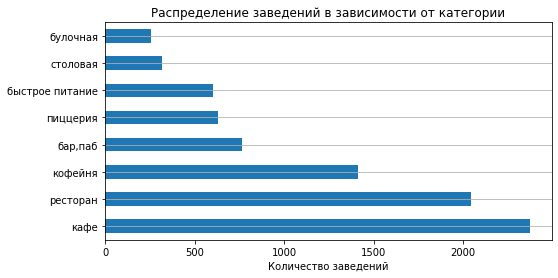

In [44]:
# Строим столбчатую диаграмму с абсолютным количеством
df['category'].value_counts().plot(kind = 'barh', figsize = (8, 4))

# Добавляем подписи
plt.title('Распределение заведений в зависимости от категории')
plt.xlabel('Количество заведений')
plt.ylabel('')

# Добавляем сетку графика
plt.grid(axis='y')

# Выводим график
plt.show()


Рассчитаем долю каждого уникального значения в столбце category.

In [45]:
# Считаем долю каждого уникального значения в столбце category
df['category'].value_counts(normalize=True)

кафе               0.282790
ресторан           0.243037
кофейня            0.168174
бар,паб            0.090931
пиццерия           0.075339
быстрое питание    0.071769
столовая           0.037491
булочная           0.030469
Name: category, dtype: float64

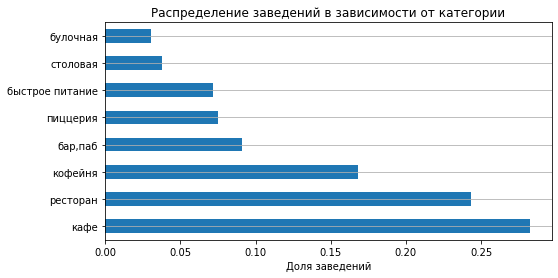

In [46]:
# Строим столбчатую диаграмму в относительных величинах
(df['category'].value_counts(normalize=True)
 .plot(kind = 'barh', figsize = (8, 4)))

# Добавляем подписи
plt.title('Распределение заведений в зависимости от категории')
plt.xlabel('Доля заведений')
plt.ylabel('')

# Добавляем сетку графика
plt.grid(axis='y')

# Выводим график
plt.show()

   
В столбце `category` представлено восемь категорий заведений:
    
- кафе и рестораны пользуются наибольшим спросом: 2376 заведений (28.3%) и 2042 заведения (24.3%) соответственно. Это показывает, что люди чаще выбирают более доступные по цене места общественного питания, но так же есть большое число ценителей ресторанного сервиса;
- не менее популярны кофейни - 1413 заведений, которые занимают 16.8% рынка и закрывают потребность любителей кофе вне дома;
- бар, паб (764 заведения, 9.1%), пиццерия (633 заведения, 7.5%) и быстрое питание (602 заведения или 7.2%) относятся к средним по численности категориям;
- низкая доля столовых (315 заведений, 3.7%) и булочных (256 заведений, 3.0%) говорит о том, что данные форматы менее конкурентны на рынке.

---

### Задача 2

Исследуем распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. 

In [47]:
# Распределение количества заведений по административным районам
df.groupby('district')['id'].nunique().sort_values(ascending = False)

district
Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: id, dtype: int64


Рассчитаем долю каждого уникального значения в столбце district.

In [48]:
# Считаем долю каждого уникального значения в столбце district
df['district'].value_counts(normalize=True)

Центральный административный округ         0.266841
Северный административный округ            0.106879
Южный административный округ               0.106165
Северо-Восточный административный округ    0.105927
Западный административный округ            0.101166
Восточный административный округ           0.094977
Юго-Восточный административный округ       0.084980
Юго-Западный административный округ        0.084385
Северо-Западный административный округ     0.048679
Name: district, dtype: float64


Создадим столбец с сокращенными названиями округов, чобы в дальнейшем визуально «разгрузить» графики от длинных надписей.

In [49]:
# Создаем столбец с сокращенными названиями округов
df['district_abb'] = df['district'].replace({'Центральный административный округ': 'ЦАО', 
                                             'Северный административный округ': 'САО', 
                                             'Южный административный округ': 'ЮАО',
                                            'Северо-Восточный административный округ': 'СВАО',
                                            'Западный административный округ': 'ЗАО',
                                            'Восточный административный округ': 'ВАО',
                                            'Юго-Восточный административный округ': 'ЮВАО',
                                            'Юго-Западный административный округ': 'ЮЗАО',
                                            'Северо-Западный административный округ': 'СЗАО'})
# Выводим 10 случайных строк
df[['district', 'district_abb']].sample(10)

,district,district_abb
1639,Северо-Восточный административный округ,СВАО
6711,Юго-Западный административный округ,ЮЗАО
1135,Северо-Восточный административный округ,СВАО
4769,Центральный административный округ,ЦАО
8212,Южный административный округ,ЮАО
2963,Восточный административный округ,ВАО
7426,Юго-Восточный административный округ,ЮВАО
8345,Восточный административный округ,ВАО
4286,Западный административный округ,ЗАО
7593,Юго-Западный административный округ,ЮЗАО


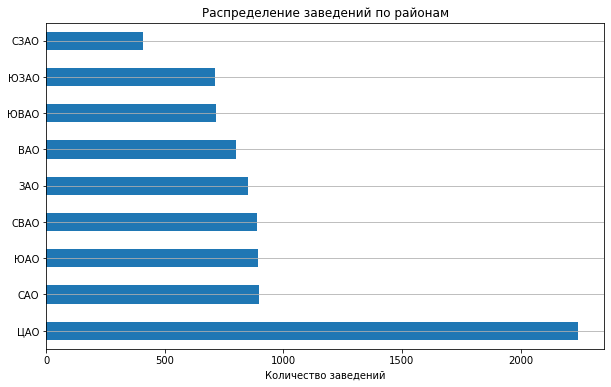

In [50]:
# Строим линейчатую диаграмму
df['district_abb'].value_counts().plot(kind = 'barh', figsize = (10, 6))

# Добавляем подписи
plt.title('Распределение заведений по районам')
plt.xlabel('Количество заведений')
plt.ylabel('')

# Добавляем сетку
plt.grid(axis="y")

# Выводим график
plt.show()

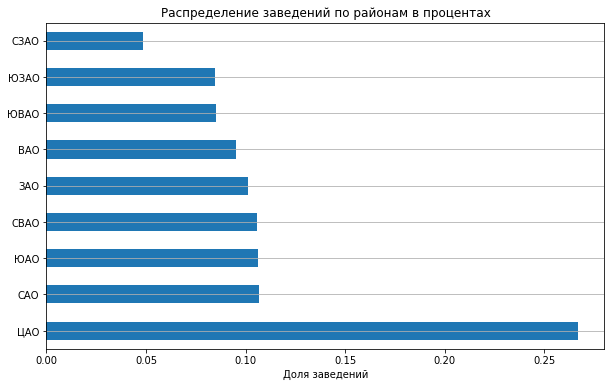

In [51]:
# Строим линейчатую диаграмму
df['district_abb'].value_counts(normalize=True).plot(kind = 'barh', figsize = (10, 6))

# Добавляем подписи
plt.title('Распределение заведений по районам в процентах')
plt.xlabel('Доля заведений')
plt.ylabel('')

# Добавляем сетку графика
plt.grid(axis="y")

# Выводим график
plt.show()

В данных представлены 9 административных районов Москвы. Наибольшее количество заведений располагается в Центральном административном округе - 2242, что составляет более четверти всего рынка (26.7%). Меньше всего мест общественного питания располагается в Северо-Западном округе - 409 объектов с долей 4.9%, в остальных округах находятся 700 - 900 точек, с долей в пределах 8.4% - 10.7%.

Рассмотрим распределение заведений каждой категории в Центральном административном округе Москвы.

In [52]:
# Фильтруем данные только для Центрального административного округа
filtered_df = df[df['district_abb'] == 'ЦАО']

# Распределение заведений по значениям столбца category
filtered_df.groupby('category')['id'].nunique().sort_values(ascending = False)

category
ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: id, dtype: int64


Рассчитаем долю значений по каждой категории в Центральном административном округе.

In [53]:
# Считаем долю значений по каждой категории
filtered_df['category'].value_counts(normalize=True)

ресторан           0.298840
кафе               0.206958
кофейня            0.190901
бар,паб            0.162355
пиццерия           0.050401
быстрое питание    0.038805
столовая           0.029438
булочная           0.022302
Name: category, dtype: float64

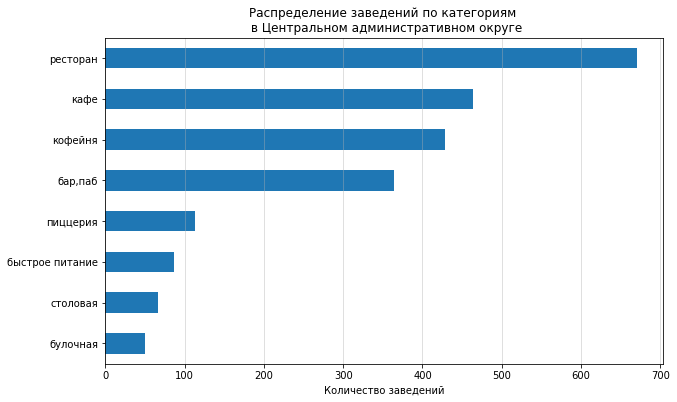

In [54]:
# Строим столбчатую диаграмму
(filtered_df['category']
 .value_counts()
 .sort_values(ascending=True)
 .plot(kind = 'barh', figsize = (10, 6)))

# Добавляем подписи
plt.title(f'Распределение заведений по категориям \n в Центральном административном округе')
plt.xlabel('Количество заведений')
plt.ylabel('')

# Добавляем сетку графика
plt.grid(axis="x", alpha=0.5)

# Выводим график
plt.show()

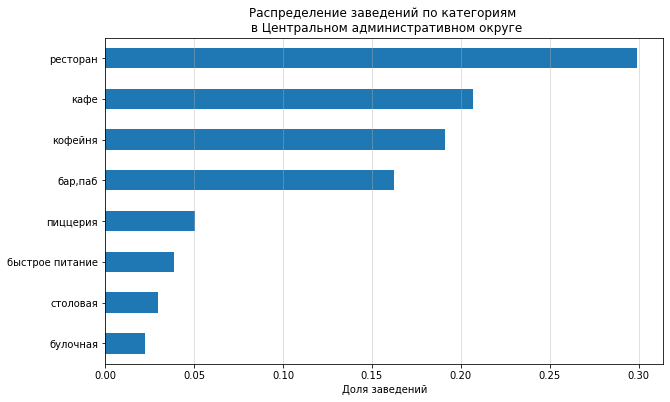

In [55]:
# Строим столбчатую диаграмму
(filtered_df['category']
 .value_counts(normalize=True)
 .sort_values(ascending=True)
 .plot(kind = 'barh', figsize = (10, 6)))

# Добавляем подписи
plt.title(f'Распределение заведений по категориям \n в Центральном административном округе')
plt.xlabel('Доля заведений')
plt.ylabel('')

# Добавляем сетку графика
plt.grid(axis="x", alpha=0.5)

# Выводим график
plt.show()


Рассмотрев подробнее распределение заведений по категориям в Центральном административном округе, можно сказать, что большим спросом пользуются рестораны: 670 заведений, что составляет 29.9% от общего числа мест в округе. Кафе и кофени также популярны, 464 (20.7%) и 428 (19.1%) заведений соответственно, можно объянить большой туристической активностью. Баров и пабов насчитывается не так много - 364 объекта (16.2%). Пиццерии (5.0%), быстрое питание (3.9%), столовые (2.9%) и булочные (2.2%) встречаются реже всего, видимо, из-за высокой аренды и низкого спроса.


Изучим распределение заведений по категориям в остальных округах, исключая Центральный.

In [56]:
# Фильтруем данные, исключая Центральный административный округ
excluded_df = df[df['district_abb'] != 'ЦАО']

# Распределение заведений по значениям столбца category
excluded_df.groupby('category')['id'].nunique().sort_values(ascending = False)

category
кафе               1912
ресторан           1372
кофейня             985
пиццерия            520
быстрое питание     516
бар,паб             400
столовая            249
булочная            206
Name: id, dtype: int64

In [57]:
# Считаем долю значений по каждой категории
excluded_df['category'].value_counts(normalize=True)

кафе               0.310390
ресторан           0.222727
кофейня            0.159903
пиццерия           0.084416
быстрое питание    0.083766
бар,паб            0.064935
столовая           0.040422
булочная           0.033442
Name: category, dtype: float64

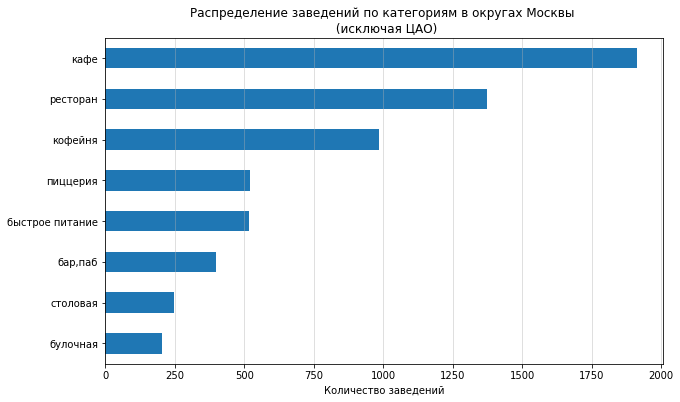

In [58]:
# Строим столбчатую диаграмму
(excluded_df['category']
 .value_counts()
 .sort_values(ascending=True)
 .plot(kind = 'barh', figsize = (10, 6)))

# Добавляем подписи
plt.title(f'Распределение заведений по категориям в округах Москвы \n (исключая ЦАО)')
plt.xlabel('Количество заведений')
plt.ylabel('')

# Добавляем сетку графика
plt.grid(axis="x", alpha=0.5)

# Выводим график
plt.show()

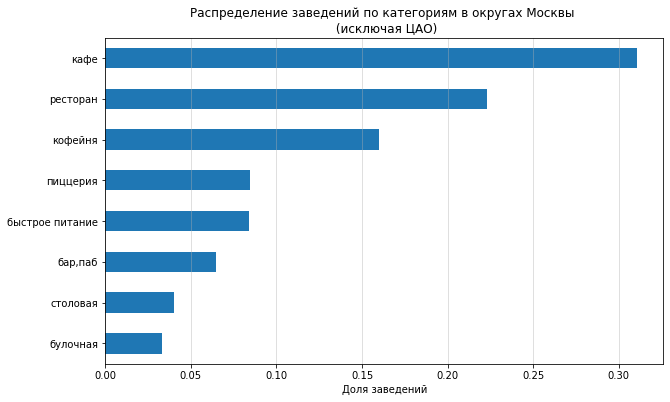

In [59]:
# Строим столбчатую диаграмму
(excluded_df['category']
 .value_counts(normalize=True)
 .sort_values(ascending=True)
 .plot(kind = 'barh', figsize = (10, 6)))

# Добавляем подписи
plt.title(f'Распределение заведений по категориям в округах Москвы \n (исключая ЦАО)')
plt.xlabel('Доля заведений')
plt.ylabel('')

# Добавляем сетку графика
plt.grid(axis="x", alpha=0.5)

# Выводим график
plt.show()

        
В центре города на первом месте находятся рестораны (29.9%), тогда как в остальных округах лидируют кафе (31.0%). Это вполне логично, так как уровень жизни в центре Москвы выше, чем на окраинах.
Доля кофеен в центре (19.1%) и за его пределами (16.0%) одинакова, потребление кофе вне дома развито в любом районе.
Бары, пабы в ЦАО занимают 16.2% рынка, а вне центра их доля падает почти в 2.5 раза - до 6.5%. ЦАО является главным центром ночной жизни столицы, и именно высокая концентрация таких заведений определяет здесь более высокий средний чек. Пиццерии (8.4%) и быстрое питание (8.4%) заметно популярнее на периферии, чем в центре, где их доли составляют 5.0% и 3.9% соответственно. В спальных районах спрос смещен в сторону быстрого и недорогого питания. 

---

### Задача 3

Изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Исследуем каких заведений больше — сетевых или несетевых, а так же какие категории заведений чаще являются сетевыми.


Рассмотрим соотношение сетевых и несетевых заведений в целом.

In [60]:
# Соотношение сетевых и несетевых заведений в целом
df['chain'].value_counts(normalize=True)*100

0    61.878124
1    38.121876
Name: chain, dtype: float64

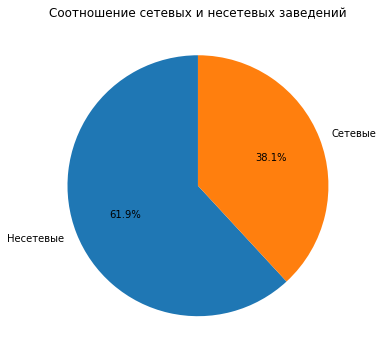

In [61]:
# Соотношение сетевых и несетевых заведений
df['chain'].value_counts(normalize=True).plot(
                            kind = 'pie', 
                            figsize = (6, 6),
                            autopct='%1.1f%%',              # Показываем проценты внутри секторов
                            startangle=90,                  # Разворачиваем график
                            labels=['Несетевые', 'Сетевые']
)

plt.title('Соотношение сетевых и несетевых заведений')
plt.ylabel('')


# Выводим график
plt.show()

    
На рынке общественного питания Москвы преобладают несетевые заведения, которые занимают большую долю - 61.9%, сетевые заведения составляют 38.1%. Возможно, локальными заведениями проще управлять и они уникальны, поэтому популярнее у людей.
    
Рассмотрим соотношение сетевых и несетевых заведений в разрезе категорий заевдений.

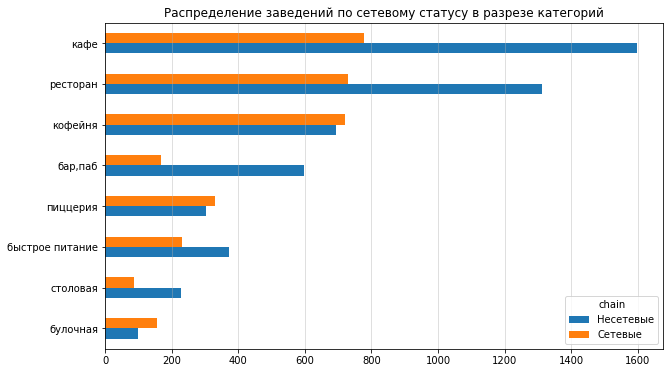

In [62]:
# Соотношение сетевых и несетевых заведений в разрезе категорий
grouped = df.groupby('category')['chain'].value_counts().unstack(fill_value=0)

# Сортируем по сумме значений в строках (общее количество заведений в категории) — по убыванию
grouped = grouped.loc[grouped.sum(axis=1).sort_values(ascending=True).index]

grouped.plot(kind = 'barh',
            title='Распределение заведений по сетевому статусу в разрезе категорий',
            legend=True,
            ylabel='Количество заведений',
            xlabel='',
            rot=0,
            figsize=(10, 6))

plt.legend(labels=['Несетевые', 'Сетевые'], title='chain')
plt.grid(axis='x',alpha=0.5)

# Выводим график
plt.show()


Анализ распределения заведений по сетевому статусу в разрезе категорий показывает:
- кафе, рестораны и бары чаще функционируют как несетевые заведения; 
- среди кофеен и пиццерий доли сетевых и несетевых точек практически равны; 
- среди булочных сетевые форматы встречаются чаще локальных; 
- столовые и места быстрого питания в большинстве случаев представлены несетевыми заведениями.

Проанализируем, какие категории заведений чаще являются сетевыми и сравним со средним значением по столбцу.

In [63]:
# Распределение сетевых заведений в разрезе категорий
df.groupby('category')['chain'].agg(['mean', 'sum']).sort_values(by = 'mean', ascending=False)

,mean,sum
category,,
булочная,0.613281,157.0
пиццерия,0.521327,330.0
кофейня,0.509554,720.0
быстрое питание,0.384743,232.0
ресторан,0.357003,729.0
кафе,0.327862,779.0
столовая,0.279365,88.0
"бар,паб",0.219895,168.0


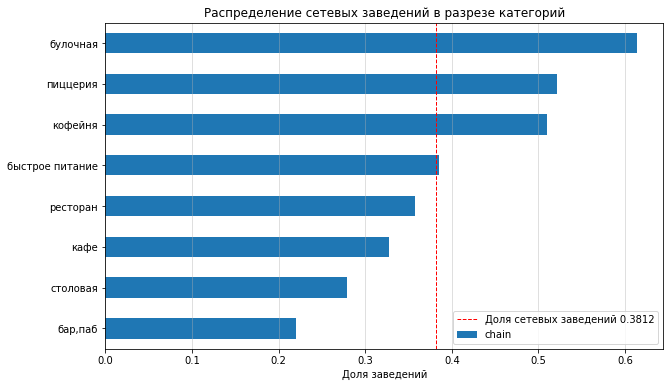

In [64]:
# Строим график столбчатой диаграммы
grouped = df.groupby('category')['chain'].mean().sort_values(ascending=True)

grouped.plot(kind = 'barh',
            title = 'Распределение сетевых заведений в разрезе категорий',
            xlabel = '',
            ylabel = 'Доля заведений',
            figsize = (10, 6),
            rot = 0)

# Рассчитываем среднее значение по доле сетевых заведений
mean_chain_share = df['chain'].mean()

# Наносим на график линию со средним значением сетевых заведений
plt.axvline(mean_chain_share, # Данные, по которым строится линия
            color='red', # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=1, # Ширина линии
            label=f'Доля сетевых заведений {round(mean_chain_share,4)}')
plt.xlabel('Доля заведений')

plt.grid(axis='x', alpha=0.5)
plt.legend()
plt.show()

    
- Булочные являются самой сетевой категорией - 61.3%, но при этом булочных в абсолютных значениях всего 157 точек. 
- Доля сетевых пиццерий (52%) и кофеен (51%) выше среднего значения, что говорит о том, что такие категории заведений удобно открывать в данном формате. При этом пиццерий в абсолютном выражении всего 330 заведений, а кофеен — 720. 
- Кафе (779 точек) и рестораны (729 точек) лидируют по общему количеству на рынке, но при этом имеют относительно низкую долю сетей (33% и 36% соответственно).
- Заведения быстрого питания реже бывают сетевыми (38%) и имеют всего 232 точки.
- Сетевых баров и столовых встречается меньше всего — 22% и 28% соответственно, и количество точек у них самое маленькое (168 и 88 объектов).

---

### Задача 4

Исследуем количество посадочных мест в заведениях. Определим для каждой категории заведений наиболее типичное для него количество посадочных мест.


In [65]:
# Изучаем статистические показатели столбца seats
df['seats'].describe(percentiles=[0.25, 0.75, 0.95, 0.99]).round(2)

count    4792.00
mean      108.36
std       122.84
min         0.00
25%        40.00
50%        75.00
75%       140.00
95%       307.00
99%       625.00
max      1288.00
Name: seats, dtype: float64

Наблюдается большой разброс данных, разница между максимальным и минимальным значениями огромна. Среднее значение завышено из-за выбросов и равно 108 местам, тогда как медиана - 75. Это указывает на большую ассиметрию в данных. 75% завдений имеют меньше 140 посадочных мест.

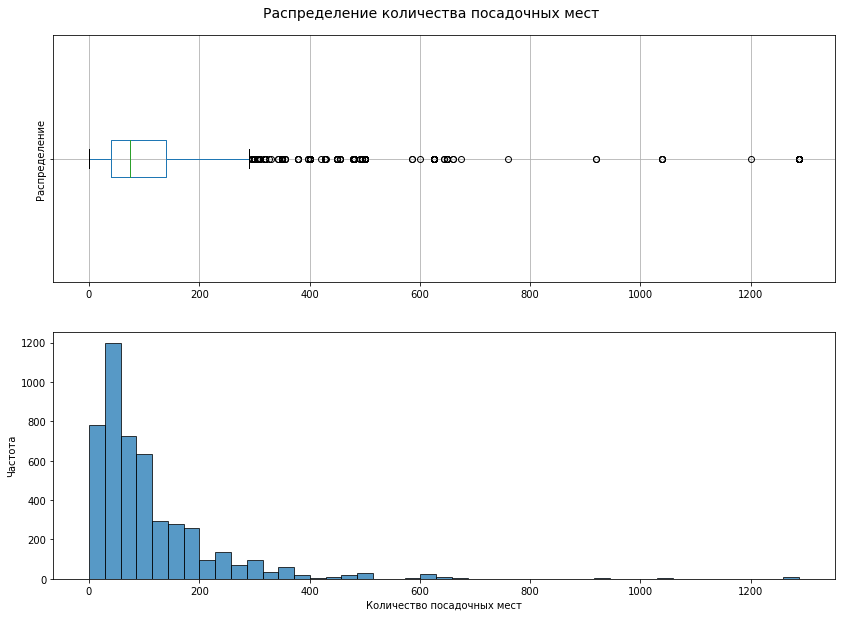

In [66]:
# Создаём контейнер графика и задаём его размер
plt.figure(figsize=(14, 10))

plt.subplot(2, 1, 1) # В окне будет 2 строки, 1 столбец, строим 1-й график
# Строим диаграмму размаха
df.boxplot(column='seats', vert=False)
# Меняем подпись 'seats' на оси Y на 'Распределение'
plt.yticks([1], ['Распределение'], rotation=90, va='center') 

plt.subplot(2, 1, 2) # Теперь строим 2-й график в той же панели
# Строим гистограмму
df['seats'].plot(
                kind='hist',
                bins=45,
                alpha=0.75,
                edgecolor='black',
                rot=0,
                subplots=True
)

# Добавляем подписи
plt.xlabel('Количество посадочных мест')
plt.ylabel('Частота')

# Добавляем общие подписи для всего окна
plt.suptitle('Распределение количества посадочных мест', fontsize=14, y=0.92)

# Выводим график
plt.show()

Распределение значения количества посадочных мест асимметричное, скошенное вправо. Минимальное количество - 0 мест, а максимальное - 1288. По гистограмме и диаграмме размаха видно, что выбросами можно считать значения выше 95-го процентиля, их следует отфильтровать, чтобы получить более достоверную статистику.

Следует проверить строки с 0 посадочных мест, чтобы убедиться, что это не ошибка в данных.

In [67]:
# Проверим данные с нулевыми сидячими местами
df[df['seats'] == 0].head(20)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7,district_abb
84,3793bd736bbb4dd08f734d53bfa57b24,meat doner kebab,булочная,"москва, улица лескова, 22",Северо-Восточный административный округ,"ежедневно, круглосуточно",4.5,0,0.0,Нет информации,Средний счёт:300 ₽,300.0,NaN,True,СВАО
177,3fb68f4204274347b94b5cb397fedce7,арамье,булочная,"москва, улица 800-летия москвы, 22, корп. 2",Северный административный округ,"ежедневно, 09:00–21:00",4.0,1,0.0,Нет информации,Нет информации,NaN,NaN,False,САО
196,bfd0d5a3a91f43e9a43f4a5fe96144f1,донер-шашлык,ресторан,"москва, улица лескова, 22",Северо-Восточный административный округ,"ежедневно, круглосуточно",4.5,0,0.0,Нет информации,Нет информации,NaN,NaN,True,СВАО
203,78f050b65d4146ef932b734db72e1e86,тандыр № 1,кафе,"москва, улица лескова, 22г",Северо-Восточный административный округ,"ежедневно, круглосуточно",4.0,1,0.0,Нет информации,Нет информации,NaN,NaN,True,СВАО
211,4636272b73bd40c59c156725492f2c05,неаполитан пицца,кафе,"москва, улица пришвина, 23",Северо-Восточный административный округ,"ежедневно, 12:00–23:00",4.3,0,0.0,Нет информации,Нет информации,NaN,NaN,False,СВАО
266,88714c537ac64189b4eba7b0b93863d3,пекарня&донер,булочная,"москва, широкая улица, 21",Северо-Восточный административный округ,"ежедневно, круглосуточно",4.1,0,0.0,Нет информации,Нет информации,NaN,NaN,True,СВАО
284,3387d4ce2194417e8fff16000df3c549,центр плов,кафе,"москва, широкая улица, 16а",Северо-Восточный административный округ,"ежедневно, круглосуточно",4.2,0,0.0,Нет информации,Нет информации,NaN,NaN,True,СВАО
290,6d0bdab2dc794308b53d999bb00465aa,шаурма,кафе,"москва, осташковская улица, 7, корп. 1",Северо-Восточный административный округ,Нет информации,3.3,0,0.0,Нет информации,Нет информации,NaN,NaN,False,СВАО
306,6453f9dbe2e84457851a9f7a4b3a267d,everest coffee,кофейня,"москва, сходненская улица, 50",Северо-Западный административный округ,"пн-чт 08:00–22:00; пт 08:00–23:00; сб,вс 09:00...",4.9,0,0.0,средние,Цена чашки капучино:200–300 ₽,NaN,250.0,False,СЗАО
337,5e92e36754c14b688923f9b8df3349af,пекарня маковка,пиццерия,"москва, сходненская улица, 35, корп. 1",Северо-Западный административный округ,"ежедневно, 08:00–22:00",4.9,0,0.0,Нет информации,Нет информации,NaN,NaN,False,СЗАО


Не стоит исключать строки с нулевыми значениями, так как некоторые заведения работают навынос и действительно могут иметь 0 посадочных мест. 

Отфильтруем значения выше 95-го процентиля, исключим выбросы.

In [68]:
# Находим 95-й процентиль
outliers = df['seats'].quantile(0.95)

# Отбираем данные, оставляя значения меньше найденного порога выбросов
new_df = df.loc[df['seats'] < outliers]

# Выводим статистические показатели после фильтрации данных
print(new_df['seats'].describe())

count    4550.000000
mean       88.127692
std        70.859617
min         0.000000
25%        40.000000
50%        70.000000
75%       120.000000
max       306.000000
Name: seats, dtype: float64


После удаления выбросов стандартное отклонение стало меньше: было 122.8, а стало 70.8. Распределение данных стало более симметричным, и это улучшает качество анализа.

Для каждой категории заведений найдем наиболее типичное количество посадочных мест.
Так как в данных между минимальным и максимальным значениями большой разброс, выберем медиану как показатель типичного количества мест.

In [69]:
# Считаем медиану - типичное количество посадочных мест для каждой категории заведения
new_df.groupby('category')['seats'].median().sort_values(ascending = False)

category
бар,паб            80.0
ресторан           80.0
столовая           72.0
кофейня            70.0
быстрое питание    60.0
кафе               55.5
пиццерия           50.0
булочная           48.5
Name: seats, dtype: float64

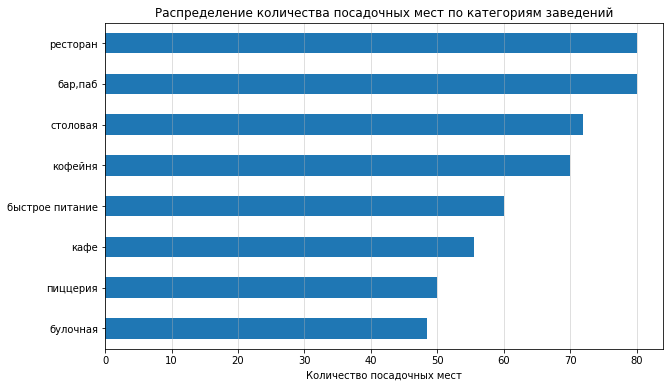

In [70]:
# Считаем медиану количества посадочных мест для каждой категории заведения
grouped = new_df.groupby('category')['seats'].median().sort_values(ascending = True)

# Строим линейчатую диаграмму распределения посадочных мест по категориям заведений
grouped.plot(kind = 'barh', figsize = (10, 6))

# Добавляем подписи            
plt.title('Распределение количества посадочных мест по категориям заведений')
plt.xlabel('Количество посадочных мест')
plt.ylabel('')

# Добавляем сетку
plt.grid(axis='x', alpha=0.5)

# Выводим график
plt.show()

Распределение количества посадочных мест показывает: 
Для баров и ресторанов типичное количество мест - 80, для столовых и кофеен в районе 70 сидячих мест, в заведениях быстрого питания и кафе примерно 60 посадочных зон, для пиццерий и булочных характерно 50 сидячих мест. 

Медианное значение в булочной достигает 50-ти мест, возникает вопрос качества данных.

---

### Задача 5

Исследуем рейтинг заведений.

In [71]:
# Изучаем статистические показатели столбца rating
df['rating'].describe()

count    8402.000000
mean        4.230017
std         0.470320
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

In [72]:
# Считаем среднее значение рейтинга по категориям заведений
df.groupby('category')['rating'].mean().sort_values(ascending=False)

category
бар,паб            4.387696
пиццерия           4.301264
ресторан           4.290402
кофейня            4.277282
булочная           4.268359
столовая           4.211429
кафе               4.124285
быстрое питание    4.050249
Name: rating, dtype: float64

Визуализируем распределение средних рейтингов по категориям заведений.

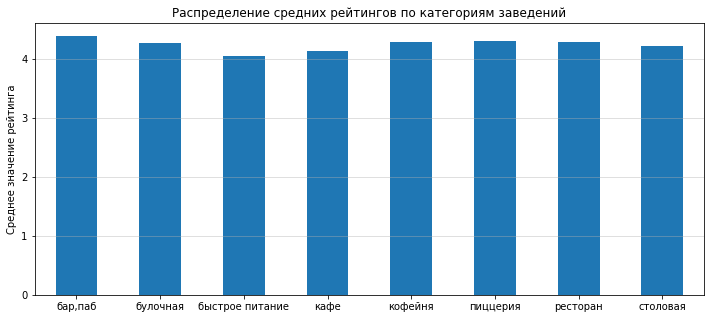

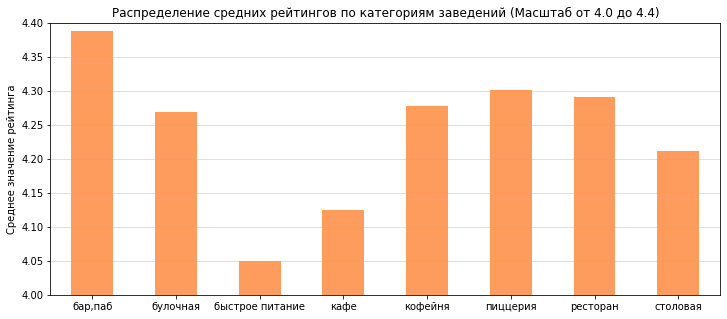

In [73]:
# 1-ый график - общий вид
# Считаем среднее значение рейтинга по категориям заведений
grouped = df.groupby('category')['rating'].mean()

# Строим столбчатую диаграмму распределения средних рейтингов по категориям
grouped.plot(kind = 'bar',
            title = 'Распределение средних рейтингов по категориям заведений',
            xlabel = '',
            ylabel = 'Среднее значение рейтинга',
            figsize = (12, 5),
            rot = 0)
plt.grid(axis='y', alpha=0.5)
# Выводим график
plt.show()

# 2-ой график - масштаб по оси у от 4-х до 4,4
plt.figure(figsize=(12, 5))
grouped.plot(kind = 'bar',
            title = 'Распределение средних рейтингов по категориям заведений (Масштаб от 4.0 до 4.4)',
            xlabel = '',
            ylabel = 'Среднее значение рейтинга',
            color = '#fd9c5d',
            rot = 0)

# Задаем рамки для оси Y, чтобы детальнее рассмотреть различия
plt.ylim(4.0, 4.4)

# Выводим график
plt.grid(axis='y', alpha=0.5)
plt.show()

Визуализация показывает, что средний рейтинг разных типов общепита примерно одинаковый и составляет 4 балла. Это значит, что посетители высоко оценивают заведения независимо от формата.

Рассмотрм каждую категорию более детально:

- Бары/пабы имеют самый высокий рейтинг - 4.39. В таких заведениях люди проводят много времени, и здесь очень важна атмосфера.
- Пиццерии (4.30), рестораны (4.29), кофейни (4.28) и булочные (4.27) также имеют хороший рейтинг. В этих форматах держится стабильно высокий уровень сервиса.
- Столовые имеют рейтинг 4.21, что является неплохим баллом для бюджетных заведений.
- Кафе имеют меньший рейтинг - 4.12. Скорее всего, в эту категорию входят заведения как с высоким уровнем обслуживания, так и простые общепиты, которые занижают средний балл.
- Самый низкий средний балл имеют заведения быстрого питания (4.05). В них упор делается больше на скорость, а не на сервис.

---

### Задача 6

Изучим, с какими данными показывают самую сильную корреляцию рейтинги заведений. Построим и визуализируем матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. 

In [74]:
# Вычисляем корреляционную матрицу для переменной rating
correlation_matrix = df[['category', 'district', 'chain', 'seats', 'price', 'is_24_7', 'rating']].phik_matrix()

# Выводим результат
correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)

interval columns not set, guessing: ['chain', 'seats', 'rating']


,rating
price,0.281253
district,0.200761
category,0.189716
is_24_7,0.150365
chain,0.107833
seats,0.000000


Небольшая корреляция рейтинга наблюдается с ценовой категорией заведения (0.28), административным районом (0.20) и категорией заведения (0.19). Для остальных признаков коэффициент корреляции снижается с 0.15 до 0 и связи между данными нет.

Визуализируем матрицу корреляции рейтинга заведений с разными данными в виде тепловой карты.

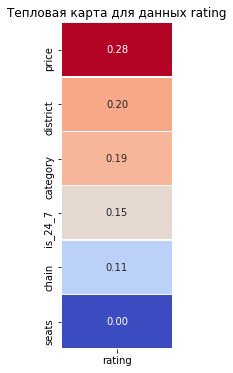

In [75]:
# Задаем размер графика
plt.figure(figsize = (2, 6))

# Сохраняем матрицу корреляции признака rating с другими признаками
df_heatmap = correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)
sns.heatmap(data = df_heatmap,
           annot = True, # Отображаем численные значения в ячейках карты
           fmt='.2f', # Форматируем значения корреляции: два знака после точки
           linewidths = 0.5, # Форматируем линию между ячейками карты
           cmap = 'coolwarm', # Устанавливаем цветовую гамму)
           cbar=False) # Отключаем цветовую шкалу

# Добавляем заголовок и подпись по оси Х
plt.title('Тепловая карта для данных rating')
plt.xlabel('')

# Выводим график
plt.show()

Проверим связь между рейтингом заведения и ценовой категорией заведения.

Оценим распределение среднего значения рейтинга заведения в зависимости от ценовой категории заведения:

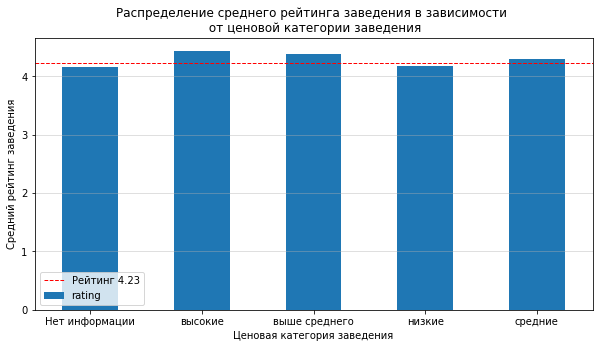

In [76]:
# Построим график столбчатой диаграммы
grouped = df.groupby('price')['rating'].mean()
grouped.plot(kind='bar',
               title=f'Распределение среднего рейтинга заведения в зависимости \n от ценовой категории заведения',
               legend=True,
               ylabel='Средний рейтинг заведения',
               xlabel='Ценовая категория заведения',
               rot=0,
               figsize=(10, 5))

# Рассчитываем среднее значение по столбцу rating
mean_rating_share = df['rating'].mean()

# Наносим на график линию со средним значением рейтинга
plt.axhline(mean_rating_share, # Данные, по которым строится линия
            color='red', # Цвет линии
            linestyle='--', # Стиль линии
            linewidth=1, # Ширина линии
            label=f'Рейтинг {round(mean_rating_share,4)}')

plt.grid(axis= 'y',alpha=0.5)
plt.legend()

# Выводим график
plt.show()

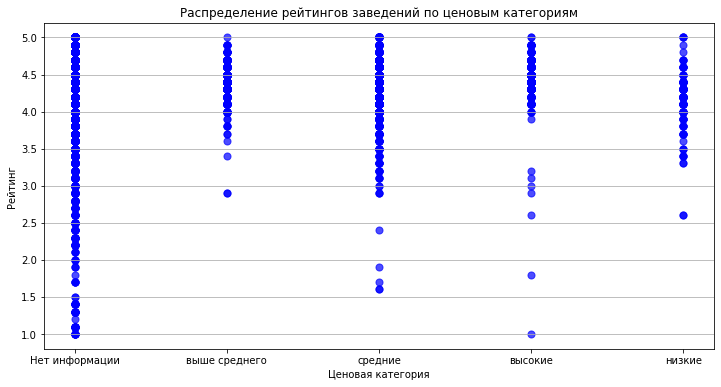

In [77]:
# Строим диаграмму рассеяния
df.plot(kind = 'scatter', 
        x = 'price', 
        y = 'rating', 
        alpha = 0.7, # Прозрачность точек
        color = 'blue',
        s = 50,
        figsize = (12, 6))

# Добавляем заголовок и подписи
plt.title('Распределение рейтингов заведений по ценовым категориям')
plt.xlabel('Ценовая категория')
plt.ylabel('Рейтинг')

# Добавляем горизонтальную сетку для точной оценки рейтинга
plt.grid(axis='y')

# Выводим график
plt.show()

Посмотрим на взаимосвязь между рейтингом завдения и административным округом.

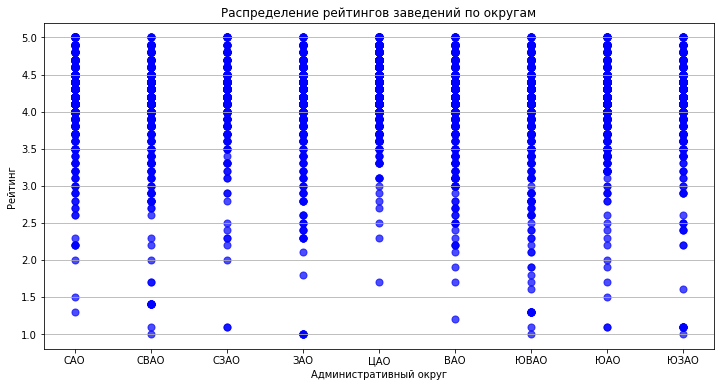

In [78]:
# Строим диаграмму рассеяния
df.plot(kind = 'scatter', 
        x = 'district_abb', 
        y = 'rating', 
        alpha = 0.7, # Прозрачность точек
        color = 'blue',
        s = 50,
        figsize = (12, 6))

# Добавляем заголовок и подписи
plt.title('Распределение рейтингов заведений по округам')
plt.xlabel('Административный округ')
plt.ylabel('Рейтинг')

# Добавляем горизонтальную сетку для точной оценки рейтинга
plt.grid(axis='y')

# Выводим график
plt.show()

В исходных данных присутствует значительный объем пропусков: для большинства заведений информация о ценовой категории отсутствует.

Из-за диспропорции данных связь между ценовым уровнем и рейтингом может оказаться ложной — на самом деле она отражает не влияние цены, а структуру самих категорий заведений. Проверим эту гипотезу.

In [79]:
# Строим таблицу сопряженности категорий заведений и ценовых сегментов
pd.crosstab(df['category'], df['price'])

price,Нет информации,высокие,выше среднего,низкие,средние
category,,,,,
"бар,паб",270,121,153,2,218
булочная,215,6,4,3,28
быстрое питание,413,3,5,22,160
кафе,1743,30,78,26,499
кофейня,937,17,14,68,377
пиццерия,322,30,40,4,237
ресторан,1025,270,268,21,458
столовая,162,1,2,10,140


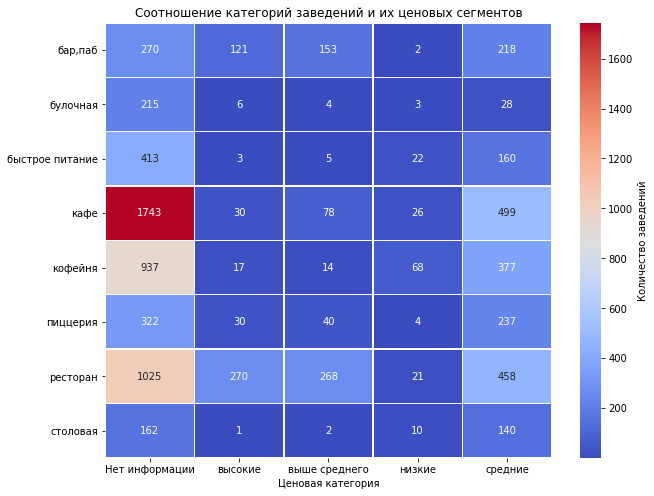

In [80]:
# Строим тепловую карту категорий заведений и их ценовых сегментов
df_heatmap= pd.crosstab(df['category'], df['price'])
plt.figure(figsize=(10, 8))

sns.heatmap(
    df_heatmap,
    annot=True, 
    fmt="d",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"label": "Количество заведений"},
)
plt.title("Соотношение категорий заведений и их ценовых сегментов")
plt.xlabel("Ценовая категория")
plt.ylabel("")

plt.show()

In [81]:
# Строим таблицу сопряженности категорий заведений и ценовых сегментов в долях
pd.crosstab(df['category'], df['price'], normalize='index')

price,Нет информации,высокие,выше среднего,низкие,средние
category,,,,,
"бар,паб",0.353403,0.158377,0.200262,0.002618,0.285340
булочная,0.839844,0.023438,0.015625,0.011719,0.109375
быстрое питание,0.684909,0.004975,0.008292,0.036484,0.265340
кафе,0.733586,0.012626,0.032828,0.010943,0.210017
кофейня,0.663128,0.012031,0.009908,0.048125,0.266808
пиццерия,0.508689,0.047393,0.063191,0.006319,0.374408
ресторан,0.501959,0.132223,0.131244,0.010284,0.224290
столовая,0.514286,0.003175,0.006349,0.031746,0.444444


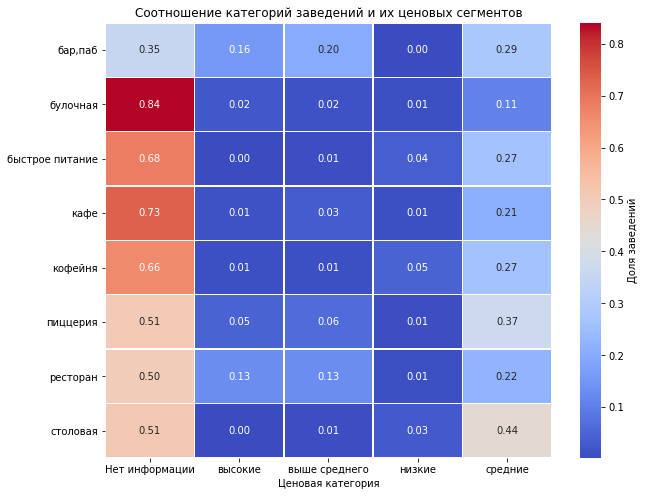

In [82]:
# Строим тепловую карту категорий заведений и их ценовых сегментов в долях
df_heatmap= pd.crosstab(df['category'], df['price'], normalize='index')

plt.figure(figsize=(10, 8))

sns.heatmap(
    df_heatmap,
    annot=True, 
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"label": "Доля заведений"},
)
plt.title("Соотношение категорий заведений и их ценовых сегментов")
plt.xlabel("Ценовая категория")
plt.ylabel("")

plt.show()


Для большинства категорий информация о ценах отсутствует, однако, по имеющимся данным можно сделать небольшой вывод:

- Значительная доля баров/пабов и ресторанов относится к ценовым категориям «высокие» и «выше среднего», формируя рейтинг в этом сегменте. 
- В ценовой категории «средние» представлены заведения всех типов, следовательно, средний рейтинг мест общественного питания в этом сегменте будет более точным. 
- Доля заведений с «низким» чеком на графике критически мала во всех категориях. 

Из-за диспропорции в данных и большого количества пропусков взаимосвязь между рейтингами заведений и ценовой категорией определить невозможно.

---

### Задача 7

Сгруппируем данные по названиям заведений и найдем топ-15 популярных сетей в Москве. Для них посчитаем значения среднего рейтинга. 

In [83]:
# Найдем топ-15 популярных сетей
grouped_df = (df[df["chain"] == 1]
              .groupby(['name','category'])
              .agg(
                  avg_rating = ('rating', 'mean')
                  ,total_count = ('id', 'count'))         
              .sort_values(by = 'total_count', ascending = False)
              .head(15)
              .reset_index()
             )
grouped_df

,name,category,avg_rating,total_count
0,шоколадница,кофейня,4.178151,119
1,домино'с пицца,пиццерия,4.169737,76
2,додо пицца,пиццерия,4.286486,74
3,one price coffee,кофейня,4.064789,71
4,яндекс лавка,ресторан,3.872464,69
5,cofix,кофейня,4.075385,65
6,prime,ресторан,4.114286,49
7,кофепорт,кофейня,4.147619,42
8,кулинарная лавка братьев караваевых,кафе,4.394872,39
9,теремок,ресторан,4.105556,36


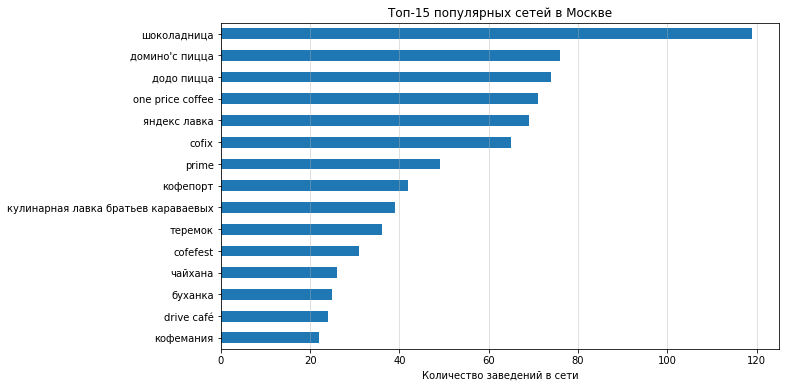

In [84]:
# Строим линейчатую диаграмму "Топ‑15 популярных сетей в Москве"
grouped_df.iloc[::-1].plot(kind = 'barh',
                           x = ('name'),
                           y = ('total_count'),
                           legend = False,
                           figsize=(10, 6)
)

# Добавляем заголовок и подпись по оси Х
plt.title('Топ‑15 популярных сетей в Москве')
plt.xlabel('Количество заведений в сети')
plt.ylabel('')

# Выводим график и сетку
plt.grid(axis='x',alpha=0.5)
plt.show()

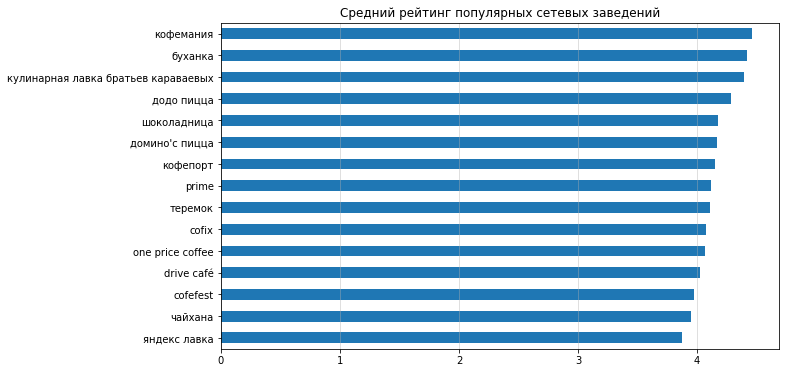

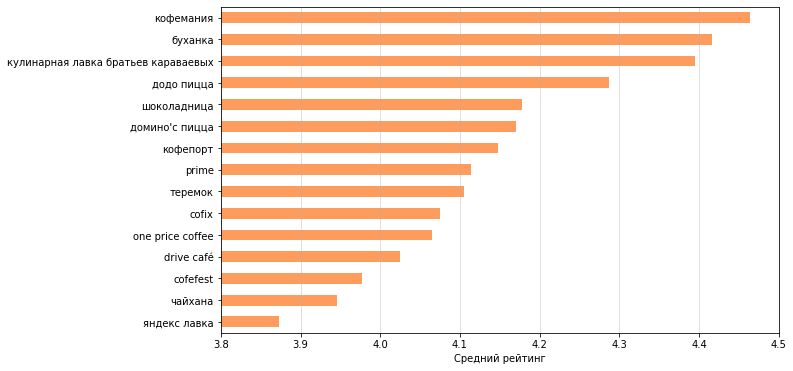

In [85]:
# Сортируем датафрейм по столбцу avg_rating
sorted_df = grouped_df.sort_values(by = 'avg_rating', ascending = False)

# 1-ый график - общий вид
# Строим линейчатую диаграмму "Средний рейтинг популярных сетевых заведений"
sorted_df.iloc[::-1].plot(kind = 'barh',
                          x = ('name'),
                          y = ('avg_rating'),
                          legend = False,
                          figsize=(10, 6)
)


# Добавляем заголовок и подпись по оси Х
plt.title('Средний рейтинг популярных сетевых заведений')
plt.ylabel('')
plt.grid(axis='x',alpha=0.5)

# 2-ой график - масштаб по оси x от 3,8 до 4,5
sorted_df.iloc[::-1].plot(kind = 'barh',
                          x = ('name'),
                          y = ('avg_rating'),
                          legend = False,
                          figsize=(10, 6),
                          color = '#fd9c5d'
)

# Задаем рамки для оси Y, чтобы детальнее рассмотреть различия
plt.xlim(3.8, 4.5)
plt.xlabel('Средний рейтинг')
plt.ylabel('')

# Выводим график и сетку
plt.grid(axis='x',alpha=0.5)
plt.show()

На основе полученных данных по топ-15 популярным сетям Москвы можно сделать следующие выводы:

- Лидером по числу точек является сеть кофейных «шоколадница», она насчитывает 119 заведений со средним рейтингом 4.18 балла. Также в число крупнейших сетей входят пиццерии «домино'с пицца» (76 точек, рейтинг 4.17) и «додо пицца» (74 точки, рейтинг 4.29). Еще одним популярным сетевым заведением является кофейня «one price coffee», она включает 71 точку, но имеет чуть более низкий рейтинг- 4.06 балла.

- Средний рейтинг выбранных заведений имеет довольно большой диапазон значений: от 3.8 до 4.4. Заведения с самым высоким рейтингом: кофейня "кофемания" - 4.46, булочная "буханка" - 4.41 и кафе «Кулинарная лавка братьев караваевых» - 4.39. Заведения с самым низким рейтингом: кофейня "яндекс лавка" - 3.87, кафе "чайхана" - 3.95 и кофейня «cofefest» - 3.98.

- Наиболее распространенные категории сетевых заведений: кофейни и пиццерии.

---

### Задача 8

Изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем цены в Центральном административном округе и других. Рассмотрим, как удалённость от центра влияет на цены в заведениях.

In [87]:
# Рассмотрим статистические показатели по столбцу middle_avg_bill
df.groupby('district_abb')['middle_avg_bill'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
district_abb,,,,,,
ВАО,260,820.63,575.0,850.90,50.0,10000.0
ЗАО,306,1053.23,1000.0,779.01,50.0,5250.0
САО,322,927.96,650.0,912.61,130.0,11000.0
СВАО,301,716.61,500.0,591.23,50.0,4500.0
СЗАО,157,822.22,700.0,595.06,120.0,2900.0
ЦАО,1060,1191.06,1000.0,920.01,0.0,7250.0
ЮАО,314,834.40,500.0,2008.64,100.0,35000.0
ЮВАО,194,654.10,450.0,566.83,30.0,3750.0
ЮЗАО,235,792.56,600.0,559.17,100.0,2750.0


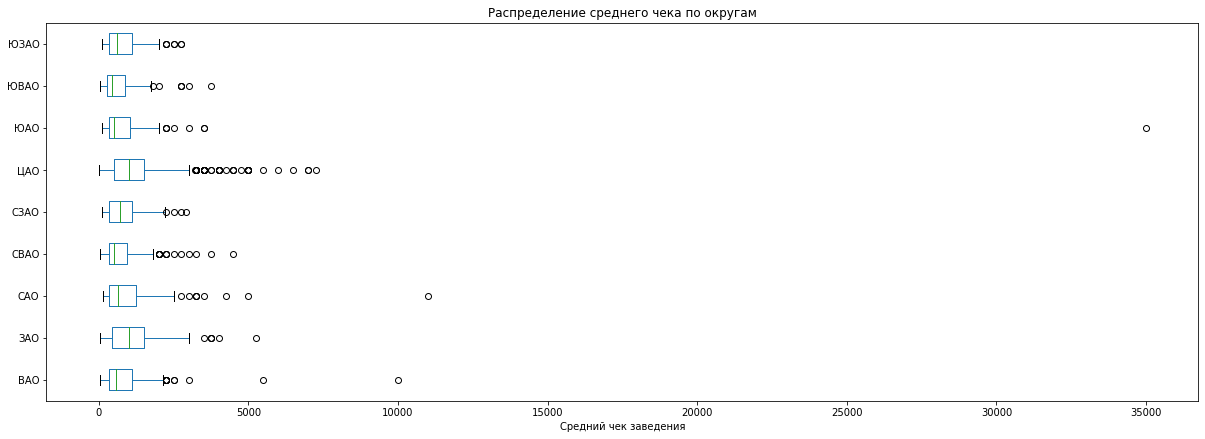

In [88]:
# Строим диаграмму размаха
boxplot = df.boxplot(column = 'middle_avg_bill',
                     by='district_abb',
                     vert = False, 
                     grid = False, 
                     figsize = (20, 7))

# Добавляем подписи
boxplot.set_title('Распределение среднего чека по округам')
boxplot.set_xlabel('Средний чек заведения')
boxplot.set_ylabel('')

plt.suptitle('') # Убираем автоматическую надпись

# Выводим график
plt.show()

В столбце `middle_avg_bill` имеются точечные выбросы, которые следует исключить, чтобы более подробно проанализировать данные.

In [89]:
# Статистические показатели столбца middle_avg_bill
df['middle_avg_bill'].describe(percentiles=[0.01, 0.95, 0.99])

count     3149.000000
mean       958.053668
std       1009.732845
min          0.000000
1%         140.000000
50%        750.000000
95%       2250.000000
99%       3750.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64

In [90]:
# Находим 99-й процентиль
outliers = df['middle_avg_bill'].quantile(0.99)

# Отбираем данные, оставляя значения меньше найденного порога выбросов
new_df = df.loc[df['middle_avg_bill'] < outliers]

# Выводим статистические показатели после фильтрации данных
print(new_df['middle_avg_bill'].describe())

count    3112.000000
mean      899.553663
std       655.005312
min         0.000000
25%       375.000000
50%       700.000000
75%      1250.000000
max      3500.000000
Name: middle_avg_bill, dtype: float64


---


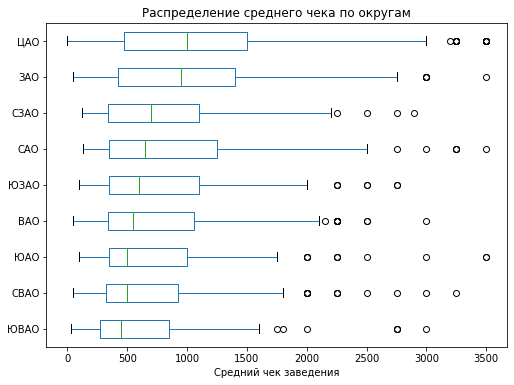

In [91]:
# Делаем new_df независимой копией
new_df = new_df.copy()

# Сортируем районы по медиане среднего чека
ordered_districts = new_df.groupby('district_abb')['middle_avg_bill'].median().sort_values().index

# Задаем этот порядок внутри самого датафрейма
new_df['district_abb'] = pd.Categorical(new_df['district_abb'], categories=ordered_districts, ordered=True)

# Строим диаграмму размаха
boxplot = new_df.boxplot(
                     column = 'middle_avg_bill',
                     by='district_abb',
                     vert = False, 
                     grid = False, 
                     figsize = (8, 6))

# Добавляем подписи
boxplot.set_title('Распределение среднего чека по округам')
boxplot.set_xlabel('Средний чек заведения')
boxplot.set_ylabel('')

plt.suptitle('') # Убираем автоматическую надпись

# Выводим график
plt.show()

In [92]:
# Рассмотрим статистические показатели по столбцу со средним чеком для каждого района Москвы
new_df.groupby('district_abb')['middle_avg_bill'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
district_abb,,,,,,
ЮВАО,193,638.06,450.0,522.29,30.0,3000.0
СВАО,299,693.81,500.0,521.99,50.0,3250.0
ЮАО,313,725.24,500.0,542.50,100.0,3500.0
ВАО,258,766.91,550.0,560.10,50.0,3000.0
ЮЗАО,235,792.56,600.0,559.17,100.0,2750.0
САО,319,873.21,650.0,657.15,130.0,3500.0
СЗАО,157,822.22,700.0,595.06,120.0,2900.0
ЗАО,301,1002.61,950.0,673.81,50.0,3500.0
ЦАО,1037,1107.30,1000.0,718.65,0.0,3500.0


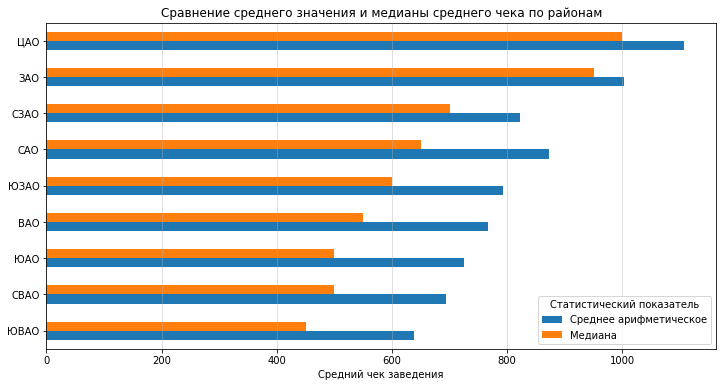

In [93]:
# Строим линейчатую диаграмму 
(new_df
 .groupby('district_abb')
 .agg({'middle_avg_bill': ['mean', 'median']})
 .sort_values(by= ('middle_avg_bill', 'median'), ascending=True)
 .plot(kind = 'barh',figsize = (12, 6)))

# Добавляем подписи и выводим график
plt.title('Сравнение среднего значения и медианы среднего чека по районам')
plt.xlabel('Средний чек заведения')
plt.ylabel('')
plt.legend(['Среднее арифметическое', 'Медиана'], title='Статистический показатель')
plt.grid(axis='x',alpha=0.5)
plt.show()

Можно сделать промежуточный вывод о том, что в некторых административных округах средний чек заведений держится на одном уровне с центральной частью Москвы.

Рассмотрим распределение значений среднего чека по всем районам Москвы, построим гистограммы для каждого округа отдельно.

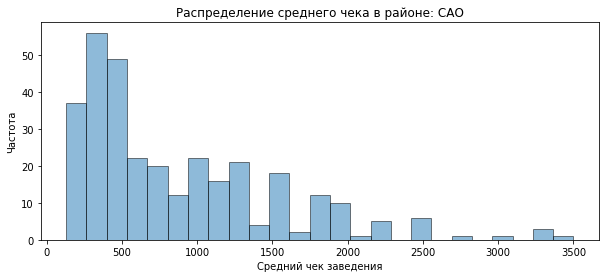

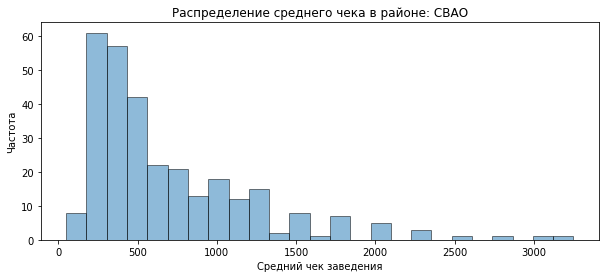

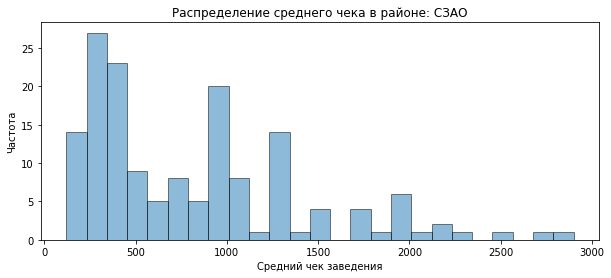

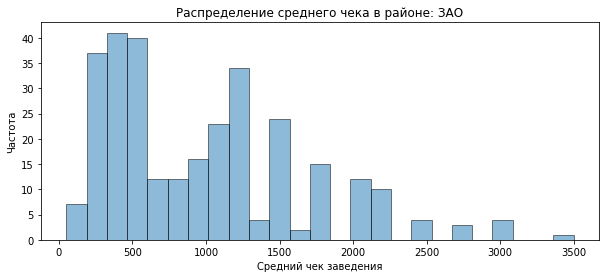

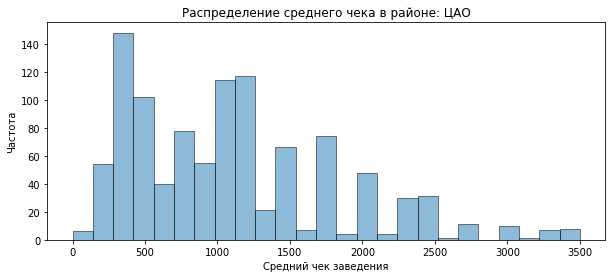

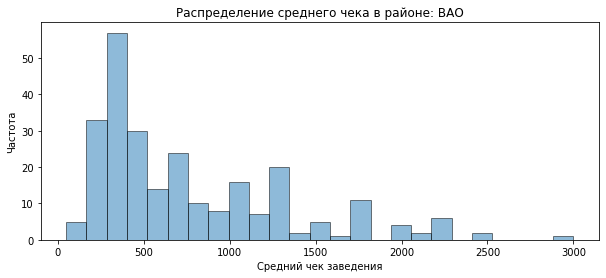

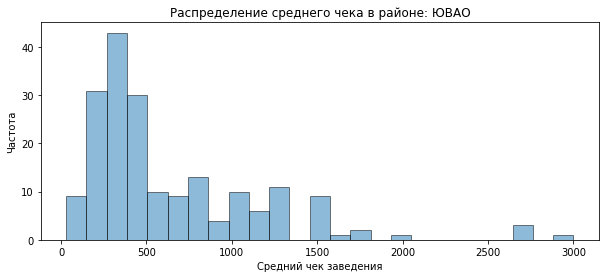

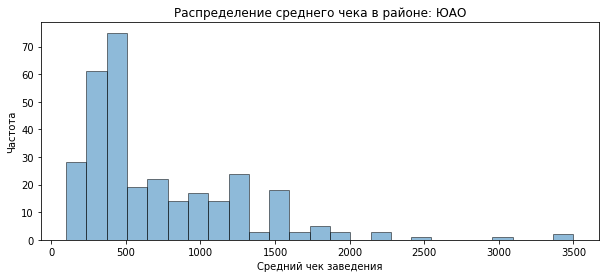

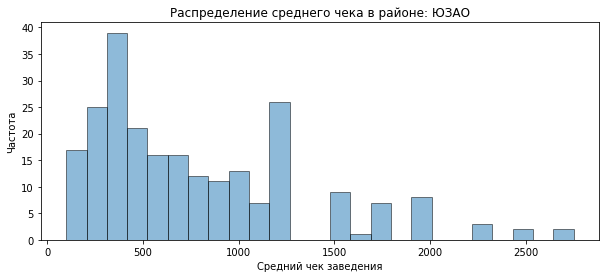

In [94]:
# Строим гистограммы для каждого района
for i in new_df['district_abb'].unique():

    # Задаем размер графика
    plt.figure(figsize=(10, 4))

    # Фильтруем данные по значению столбца district
    new_df.loc[new_df['district_abb'] == i, 'middle_avg_bill'].plot(
        kind='hist',
        bins=25,
        alpha=0.5,
        edgecolor='black'
    )

    # Добавляем подписи и выводим график
    plt.title(f'Распределение среднего чека в районе: {i}')
    plt.xlabel('Средний чек заведения')
    plt.ylabel('Частота')
    plt.show()

В Центральном административном округе находится почти половина всех заведений (1037 точек), а средний чек (1107 руб.) и медиана (1000 руб.) являются самыми высокими в городе. Западный округ держится на уровне Центрального: средний чек составляет 1002 руб., а медиана — 950 руб. Это говорит о том, что на окраинах есть цены, сопоставимые с центром.

Самый доступный общепит находится в Юго-Восточном и Северо-Восточном округах, там зафиксированы самые низкие показатели в городе: средний чек 638 руб. и 693 руб. и медиана 450 руб. и 500 руб. соответственно, эти показатели почти в 2 раза ниже чем в центре Москвы.

Гистограммы показывают, что во всех районах, кроме Центрального и Западного распределение среднего чека неравномерное и скошенное вправо, это говорит о том, что в этих округах в основном доступные по цене места общественного питания, но так же есть небольшое количество заведений ресторанного уровня. В Центральном и Западном округах  распределение чеков более равномерное за счет явного преобладания заведений премиум-класса.

В удаленных от центра районах, кроме Западного, наблюдается большая разница между медианой и средним значением. Это свидетельствует о том, что в районах основная масса заведений вполне доступна, но единичные элитные рестораны со средним чеком 3000-3500 руб. влияют на увеличесние среднего значения. В отличие от Центрального и Западного районов, где распределение  категорий заведений и цен в них равномерное и разница между медианой и средним значением минимальна.

Во всех округах стандартное отклонение очень высокое (от 521 до 718 руб.), это указывает на огромное внутреннее разнообразие рынка, в каждом районе можно найти как бюджетные заведения, так и премиальный сегмент.

Распределение заведений по категориям в Центральном административном округе.

In [95]:
# Распределение заведений по категориям в ЦАО
(df[df['district_abb'] =='ЦАО']
 .groupby('category')['id']
 .nunique()
 .sort_values(ascending = False))

category
ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: id, dtype: int64

In [96]:
# Фильтруем данные, исключая Центральный административный округ
# Распределение заведений по категориям
(df[df['district_abb'] != 'ЦАО']
 .groupby('category')['id']
 .nunique()
 .sort_values(ascending = False))

category
кафе               1912
ресторан           1372
кофейня             985
пиццерия            520
быстрое питание     516
бар,паб             400
столовая            249
булочная            206
Name: id, dtype: int64

In [97]:
# Медиана среднего чека по районам 
(new_df
 .groupby('district_abb')
 .agg({'middle_avg_bill': 'median'})
 .sort_values(by = "middle_avg_bill", ascending=False))

,middle_avg_bill
district_abb,
ЦАО,1000.0
ЗАО,950.0
СЗАО,700.0
САО,650.0
ЮЗАО,600.0
ВАО,550.0
СВАО,500.0
ЮАО,500.0
ЮВАО,450.0



Рассмотрим медиану среднего чека двух самых популярных категорий заведений: рестораны и кафе в ЦАО и других округах.

In [98]:
# Считаем средний чек для категории "ресторан" по всем районам Москвы
(new_df[new_df['category'] == 'ресторан']
 .groupby('district_abb')
 .agg({'middle_avg_bill': ['count','median']})
 .sort_values(by = ("middle_avg_bill", 'median'), ascending=False))

middle_avg_bill        
                       count  median
district_abb                        
СЗАО                      48  1250.0
ЗАО                      112  1250.0
ЦАО                      389  1250.0
САО                       94  1162.5
ЮЗАО                      78  1050.0
ВАО                       67  1000.0
ЮАО                       89   950.0
ЮВАО                      54   925.0
СВАО                      83   800.0

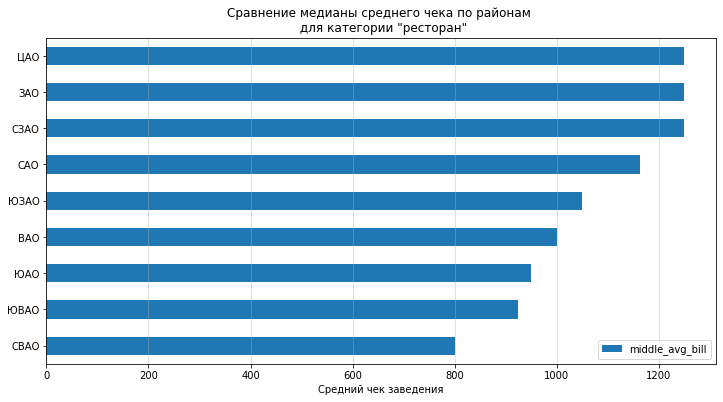

In [99]:
# Строим линейчатую диаграмму 
(new_df[new_df['category'] == 'ресторан']
 .groupby('district_abb')
 .agg({'middle_avg_bill': 'median'})
 .sort_values(by = 'middle_avg_bill')
 .plot(kind = 'barh',figsize = (12, 6)))

# Добавляем подписи и выводим график
plt.title('Сравнение медианы среднего чека по районам \n для категории "ресторан"')
plt.xlabel('Средний чек заведения')
plt.ylabel('')
plt.grid(axis='x',alpha=0.5)
plt.show()

In [100]:
# Считаем средний чек для категории "кафе" по всем районам Москвы
(new_df[new_df['category'] == 'кафе']
 .groupby('district_abb')
 .agg({'middle_avg_bill': ['count','median']})
 .sort_values(by = ("middle_avg_bill", 'median'), ascending=False))

middle_avg_bill       
                       count median
district_abb                       
ЦАО                      210  700.0
СЗАО                      32  650.0
ЗАО                       62  625.0
ЮАО                       62  600.0
САО                       68  550.0
СВАО                      76  462.5
ВАО                       68  450.0
ЮЗАО                      58  450.0
ЮВАО                      56  387.5

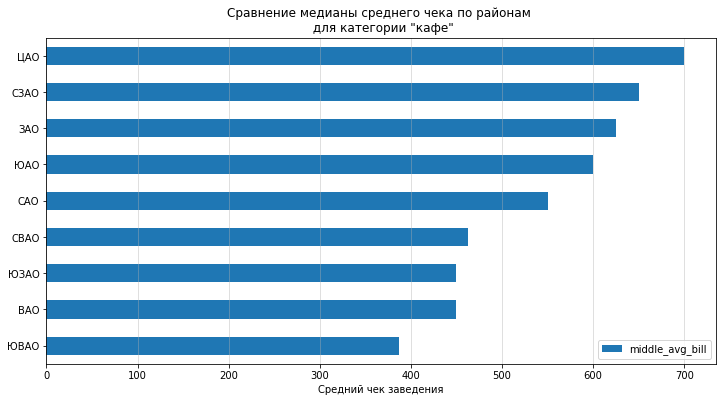

In [101]:
# Строим линейчатую диаграмму 
(new_df[new_df['category'] == 'кафе']
 .groupby('district_abb')
 .agg({'middle_avg_bill': 'median'})
 .sort_values(by = 'middle_avg_bill')
 .plot(kind = 'barh',figsize = (12, 6)))

# Добавляем подписи и выводим график
plt.title('Сравнение медианы среднего чека по районам \n для категории "кафе"')
plt.xlabel('Средний чек заведения')
plt.ylabel('')
plt.grid(axis='x',alpha=0.5)
plt.show()


Исходя из полученных результатов, можно сделать важный вывод о том, что общий средний чек в Москве зависит не столько от удаленности района от центра, а от формата заведений. В центре сосредоточено больше ресторанов, следовательно, и общий чек по району будет выше. На окраинах же средний чек в самих заведениях, по конкертным категориям, практически не отличается от центрального. Однако из-за того, что там находится больше бюджетных мест общественного питания, итоговый средний чек по всему району оказывается ниже.

---

### Промежуточный вывод


Исходный объем данных после объединения двух датасетов составил 8406 строк. В результате предобработки было удалено всего 0.047% записей, поэтому в итоговом исследовании приняли участие 8402 строки.

Анализ взаимосвязи данных показал:

- Все заведения Москвы, исследуемые в данных, делятся на восемь категорий: наибольшим спросом пользуются кафе и рестораны; не менее популярны кофейни; бары/пабы, пиццерии и заведения быстрого питания являются средними по численности; наименее конкурентными считаются столовые и булочные.  

- В данных представлены девять административных округов. Наибольшее количество заведений располагается в Центральном административном округе, большим спросом пользуются рестораны. В то время как в остальных округах лидируют кафе. Это вполне логично, так как уровень жизни в центре Москвы выше, чем на окраинах.

- В общем объеме рынка доля несетевых заведений преобладает над сетевыми — 61.9% против 38.1% соответственно. Булочные и пиццерии чаще развиваются как сети, хотя общее количество точек такого формата невелико. Кофейни также предпочитают открывать в сетевом формате и данный сегмент включает в себя большое число объектов.

- Типичное количество посадочных мест для баров и ресторанов составляет 80 мест, для столовых и кофеен в районе 70 сидячих мест, в заведениях быстрого питания и кафе примерно 60 посадочных зон, для пиццерий и булочных характерно 50 сидячих мест.

- Средний рейтинг разных типов общепита составляет 4 балла, это значит, что посетители высоко оценивают заведения независимо от формата. Самый высокий рейтинг имеют бары/пабы (4.39), самый низкий - заведения быстрого питания (4.05). Из-за диспропорции в данных и большого количества пропусков взаимосвязь между рейтингами заведений и ценовой категорией определить невозможно.

- Лидером по числу точек является сеть кофейных «шоколадница», в число крупнейших сетей входят пиццерии «домино'с пицца» и «додо пицца», а также кофейни «one price coffee». Средний рейтинг топ-15 популярных сетей Москвы имеют довольно большой диапазон значений: от 3.8 до 4.4. Наиболее распространенные категории сетевых заведений: кофейни и пиццерии.

- Удаленность от центра не является показателем низких цен. В Центральном и Западном округах сосредоточено больше  ресторанов, следовательно и общий чек по району будет выше. На окраинах же средний чек в самих заведениях, по конкертным категориям, практически не отличается от центрального. Однако из-за того, что там находится больше бюджетных мест общественного питания, итоговый средний чек по всему району оказывается ниже. 

## 4. Итоговый вывод и рекомендации


В ходе работы проанализировали данные 8406 строк, в которых представлена информация о заведениях общественного питания Москвы и среднем чеке в этих заведениях. Провели исследовательский анализ данных, чтобы выбрать подходящее место для открытия новой точки.

После проведенного анализа данных, можно сделать следующие выводы:
- Самыми популярными категориями в Москве являются кафе, рестораны и кофейни.
- Наибольшее количество заведений располагается в Центральном административном округе.
- Доля несетевых заведений преобладает над сетевыми, 61.9% против 38.1% соответственно. Булочные, кофейни и пиццерии чаще являются сетевыми.
- Ресторанам и барам требуется больше посадочных мест, чем бюджетным заведениям с быстрым потоком клиентов.
- Средний рейтинг всех категорий заведений составляет 4 балла. Самую высокую оценку имеют бары/пабы.
- Цены в заведениях зависят от их категории и не связаны с удалённостью от центра города. В Центральном и Западном округах средний чек в заведениях выше, чем во всех остальных районах города, так как там соосредоточено большое количество ресторанов. 

**Рекомендации:**

- Если планируется открытие сетевого заведения, то в качестве формата лучше выбирать кофейни или пиццерии. Для несетевого подойдут категории ресторанов и баров.
- Новое место выгодно расположить в Центральном или Западном округах, так как там сосредоточена наиболее обеспеченная аудитория. При желании избежать конкуренции стоит рассмотреть окраины города, учитывая при этом, что средний чек там будет ниже.